In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_parquet("newtonian_trials.pq")
mask = ~np.isinf(df["sma"])

In [2]:
def plot_pdf_wrapper(data, bins='auto', ax_pdf=None):
    """
    Plot a normalized PDF (max ~1) and ECDF for given data.
    
    Parameters
    ----------
    data : array-like
        Input 1D data.
    bins : str or int or sequence, optional
        Binning strategy for the histogram. Default 'auto' (uses numpy's automatic bin selection).
    ax_pdf, ax_ecdf : matplotlib Axes, optional
        Axes to plot on. If None, new figure and axes are created.
    """
    data = np.asarray(data)
    
    # Create axes if not provided
    if ax_pdf is None or ax_pdf is None:
        fig, ax_pdf = plt.subplots()
    
    # --- PDF ---
    counts, edges = np.histogram(data, bins=bins)
    counts = counts * 1.
    counts /= counts.max()  # scale so max ~ 1
    # Repeat counts to match step boundaries
    x = np.repeat(edges, 2)
    y = np.hstack(([0], np.repeat(counts, 2), [0]))  # drop to 0 outside range
    ax_pdf.plot(x, y)
    return ax_pdf, bins


(array([1.57257435, 0.44930696, 1.57257435, 1.34792087, 2.02188131,
        1.57257435, 4.04376262, 4.49306958, 4.49306958, 0.22465348]),
 array([0.42470081, 0.4705905 , 0.51648019, 0.56236988, 0.60825957,
        0.65414926, 0.70003895, 0.74592864, 0.79181833, 0.83770802,
        0.88359771]),
 [<matplotlib.patches.Polygon at 0x79bc96f76b10>])

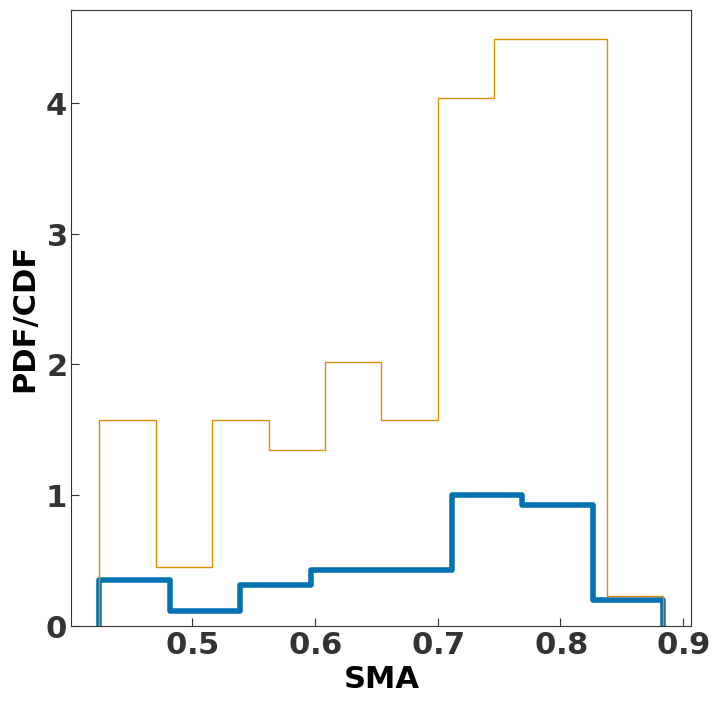

In [14]:
fig,ax = plt.subplots()
# ax.set_ylim(0, 1.1)
ax.set_xlabel("SMA")
ax.set_ylabel("PDF/CDF")

# bins = "auto"
ax_pdf, bins = plot_pdf_wrapper(df["sma"][mask], ax_pdf=ax, bins=bins)
# ax.ecdf(df["sma"][mask], linestyle="--")
ax.hist(df["sma"][mask], density=True, histtype="step")

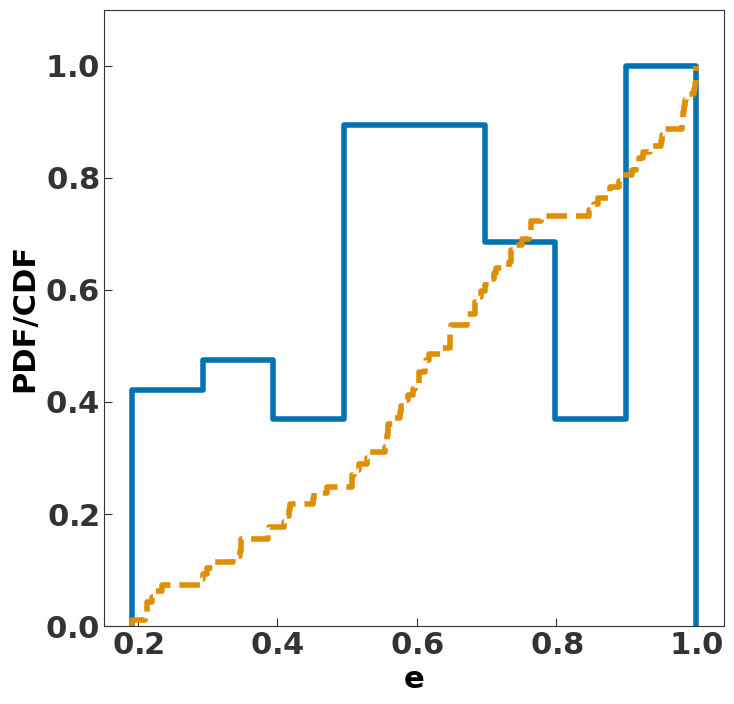

In [4]:
fig,ax = plt.subplots()
ax.set_ylim(0, 1.1)
ax.set_xlabel("e")
ax.set_ylabel("PDF/CDF")

bins = "auto"
ax_pdf, bins = plot_pdf_wrapper(df["ecc"][mask], ax_pdf=ax, bins=bins)
ax.ecdf(df["ecc"][mask], linestyle="--")

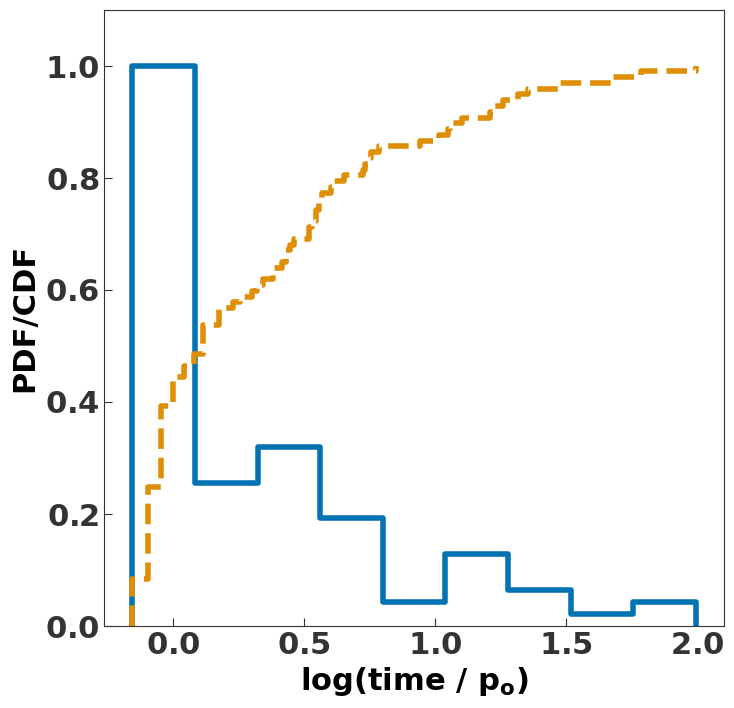

In [ ]:
fig,ax = plt.subplots()
ax.set_ylim(0, 1.1)
ax.set_xlabel("log(time / $p_o$)")
ax.set_ylabel("PDF/CDF")

pin = 2 * np.pi * 1. / (2.**.5)
pout = 2 * np.pi * 10.**1.5 / (3.**.5)
##Normalizing time elapsed by the initial tertiary period...
bins="auto"
ax_pdf, bins = plot_pdf_wrapper(np.log10(df["time"][mask] / pout), ax_pdf=ax, bins=bins)
ax.ecdf(np.log10(df["time"][mask] / pout), linestyle="--")